# **Adult Census Income 300 Samples**

Loading and preprocessing Adult dataset...
Shapes -> X_train_bal: (31640, 30), X_val_s: (5210, 30), X_test_s: (6513, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 10.0}, Best score: 0.9577
Optimal threshold: 0.540 (F1: 0.7040)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.540

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (300 samples) in 5.215s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (300 samples) in 9.331s
Memory after CKKS-Single: 1711.94 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (300 samples) in 4.157s
Memory after CKKS-Batched: 1711.94 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8581     0.7007  0.7168  0.7087   0.9169  0.8036   0.3167  0.0998
1      Paillier-Hybrid    0.8633     0.7000  0.7671 

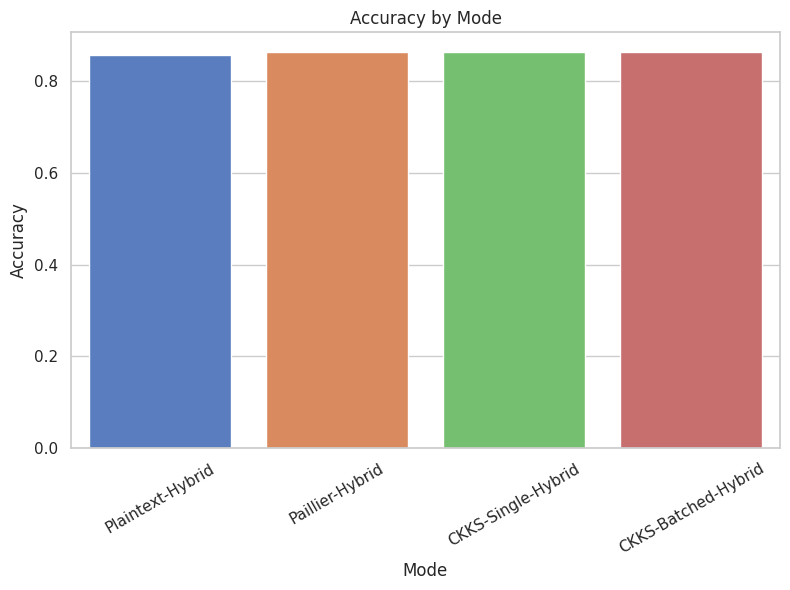

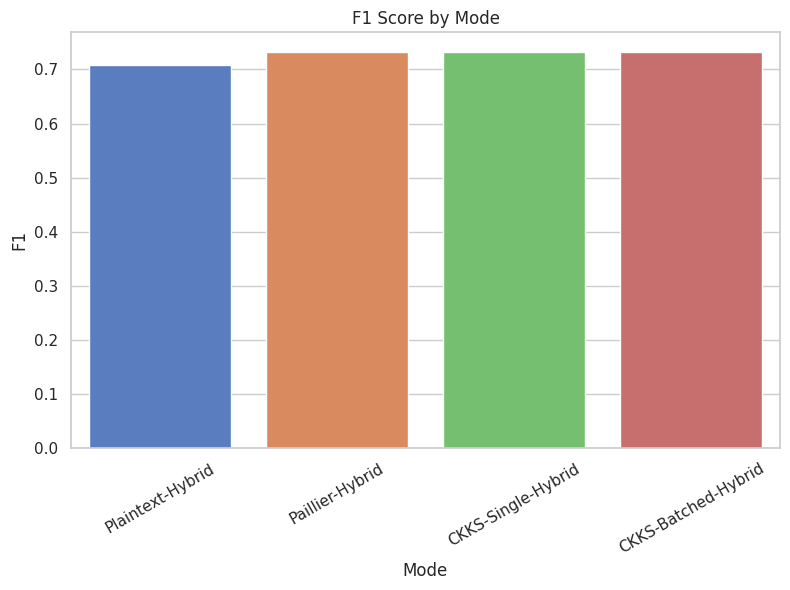

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Adult Census Income (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Adult Census Income)
# ========================================
print("Loading and preprocessing Adult dataset...")

# Auto-download Adult dataset
df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None, na_values=" ?", skipinitialspace=True
)

# Add column names
df.columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

# Drop rows with missing values
df = df.dropna()

# target
y = df["income"].apply(lambda x: 1 if ">50K" in str(x) else 0)
df = df.drop(columns=["income"])

# Basic feature engineering
df["age_binned"] = pd.cut(df["age"], bins=5, labels=False)
df["hours_binned"] = pd.cut(df["hours-per-week"], bins=5, labels=False)
df["capital_gain_binned"] = pd.cut(df["capital-gain"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df["capital_loss_binned"] = pd.cut(df["capital-loss"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# One-hot encode categorical variables
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 300
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **Adult Census Income 500 Samples**

Loading and preprocessing Adult dataset...
Shapes -> X_train_bal: (31640, 30), X_val_s: (5210, 30), X_test_s: (6513, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 10.0}, Best score: 0.9569
Optimal threshold: 0.590 (F1: 0.7047)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.590

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (500 samples) in 8.136s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (500 samples) in 16.393s
Memory after CKKS-Single: 1718.85 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (500 samples) in 5.522s
Memory after CKKS-Batched: 1718.85 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8595     0.7144  0.6939  0.7040   0.9147  0.7998   0.3225  0.1022
1      Paillier-Hybrid    0.8680     0.7519  0.7405

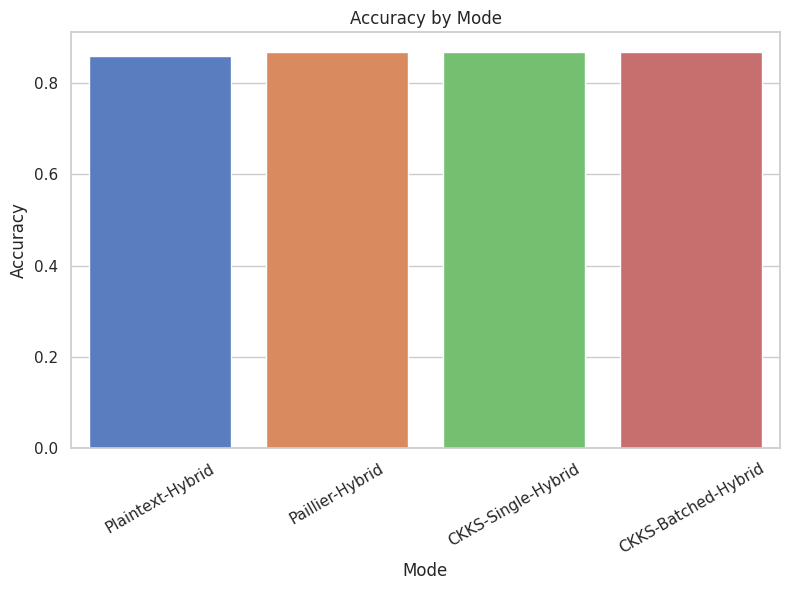

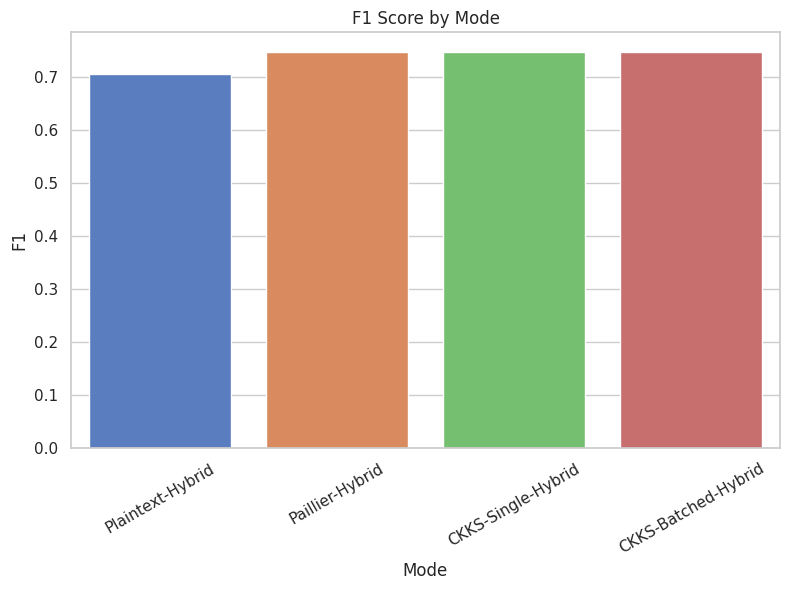

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Adult Census Income (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Adult Census Income)
# ========================================
print("Loading and preprocessing Adult dataset...")

# Auto-download Adult dataset
df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None, na_values=" ?", skipinitialspace=True
)

# Add column names
df.columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

# Drop rows with missing values
df = df.dropna()

# target
y = df["income"].apply(lambda x: 1 if ">50K" in str(x) else 0)
df = df.drop(columns=["income"])

# Basic feature engineering
df["age_binned"] = pd.cut(df["age"], bins=5, labels=False)
df["hours_binned"] = pd.cut(df["hours-per-week"], bins=5, labels=False)
df["capital_gain_binned"] = pd.cut(df["capital-gain"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df["capital_loss_binned"] = pd.cut(df["capital-loss"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# One-hot encode categorical variables
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 500
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **Adult Census Income 1000 Samples**

Loading and preprocessing Adult dataset...
Shapes -> X_train_bal: (31640, 30), X_val_s: (5210, 30), X_test_s: (6513, 30)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 10.0}, Best score: 0.9569
Optimal threshold: 0.590 (F1: 0.7051)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.590

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (1000 samples) in 16.535s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (1000 samples) in 33.065s
Memory after CKKS-Single: 1732.69 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (1000 samples) in 11.240s
Memory after CKKS-Batched: 1732.69 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8578     0.7084  0.6958  0.7021   0.9158  0.7990   0.3202  0.1017
1      Paillier-Hybrid    0.8620     0.7326  0

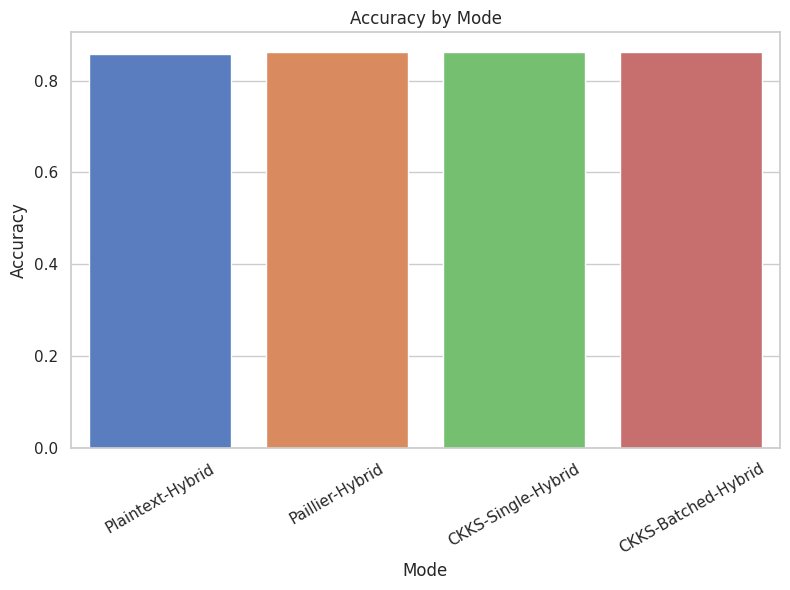

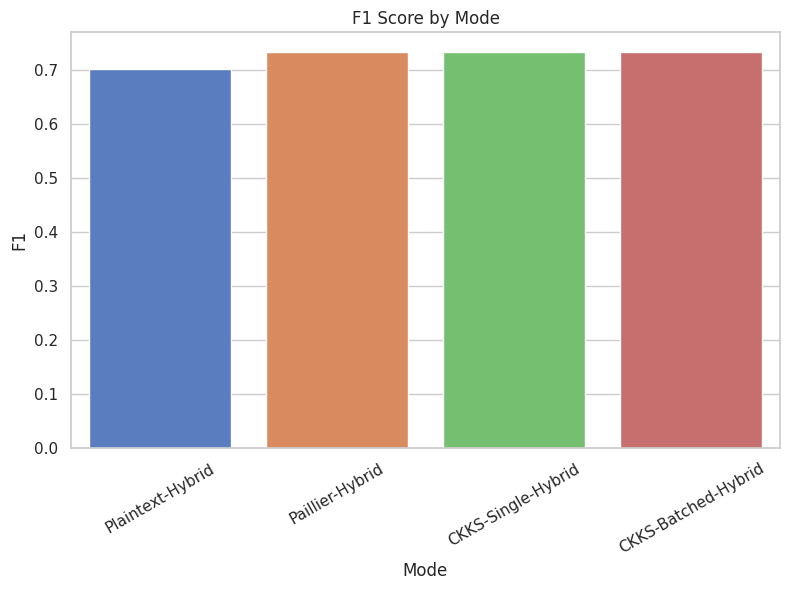

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Adult Census Income (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Adult Census Income)
# ========================================
print("Loading and preprocessing Adult dataset...")

# Auto-download Adult dataset
df = pd.read_csv(
    "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    header=None, na_values=" ?", skipinitialspace=True
)

# Add column names
df.columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

# Drop rows with missing values
df = df.dropna()

# target
y = df["income"].apply(lambda x: 1 if ">50K" in str(x) else 0)
df = df.drop(columns=["income"])

# Basic feature engineering
df["age_binned"] = pd.cut(df["age"], bins=5, labels=False)
df["hours_binned"] = pd.cut(df["hours-per-week"], bins=5, labels=False)
df["capital_gain_binned"] = pd.cut(df["capital-gain"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)
df["capital_loss_binned"] = pd.cut(df["capital-loss"].replace([np.inf, -np.inf], np.nan).fillna(0), bins=5, labels=False)

# One-hot encode categorical variables
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - keep top 30 features
selector = SelectKBest(score_func=f_classif, k=min(30, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split (stratified)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale (fit on train only)
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance classes on train only
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 1000
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **Diabetes Dataset 300 Samples**

Dataset loaded. Shape: (101766, 50)
Shapes -> X_train_bal: (115720, 50), X_val_s: (16283, 50), X_test_s: (20354, 50)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.01}, Best score: 0.9733
Optimal threshold: 0.200 (F1: 0.2567)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.200

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (300 samples) in 5.265s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (300 samples) in 9.847s
Memory after CKKS-Single: 1985.85 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (300 samples) in 3.028s
Memory after CKKS-Batched: 1985.85 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8815     0.3357  0.0630  0.1060   0.6203  0.1829   0.4240  0.1028
1      Paillier-Hybrid    0.9033     0.1250  0.0435  0.0

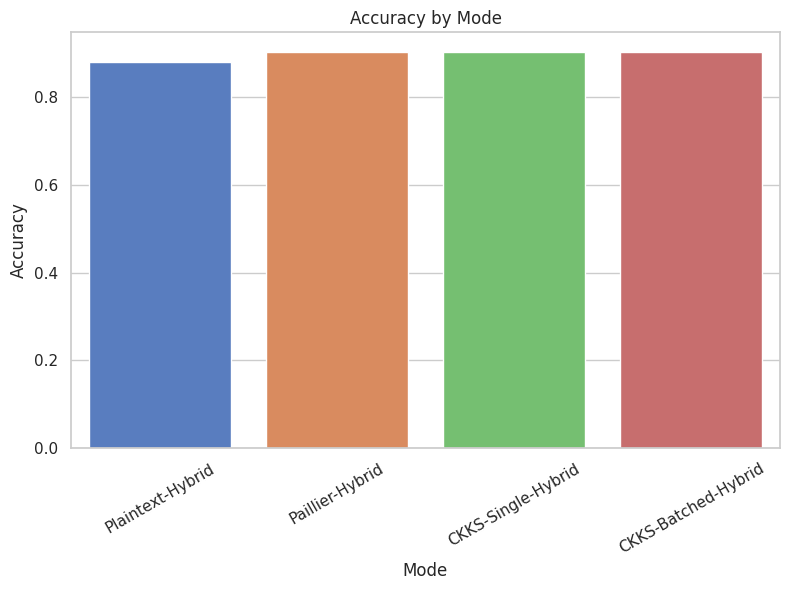

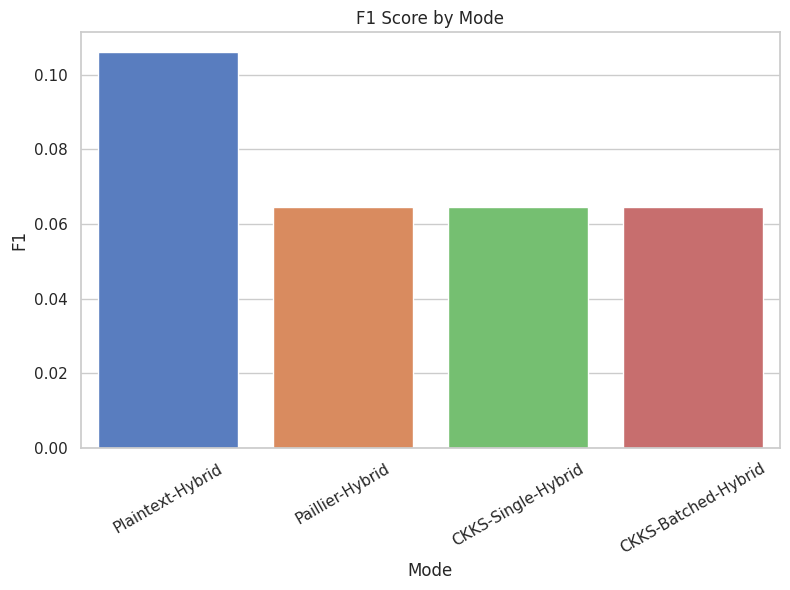

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Diabetes 130-US hospitals (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc
import os
import urllib.request # Import urllib.request
import zipfile # Import zipfile

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Diabetes 130 dataset)
# ========================================

# Download and extract Diabetes 130 dataset if not already present
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00296/dataset_diabetes.zip"
zip_file = "dataset_diabetes.zip"
csv_file = "dataset_diabetes/diabetic_data.csv"  # <-- FIXED PATH

if not os.path.exists(csv_file):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_file)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall(".")
        print("Files extracted:", zip_ref.namelist())

    print("Downloaded and extracted dataset.")

# Now read the CSV
df = pd.read_csv(csv_file)
print("Dataset loaded. Shape:", df.shape)
# Drop identifier columns
drop_cols = ["encounter_id", "patient_nbr", "weight", "payer_code", "medical_specialty"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Target: readmitted (<30 = 1, else 0)
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if str(x).strip() == "<30" else 0)
y = df["readmitted"]
df = df.drop(columns=["readmitted"])

# Handle missing values ("?")
df = df.replace("?", np.nan)
df = df.dropna(axis=1, thresh=0.9*len(df))
df = df.fillna("Unknown")

# Feature engineering (bin numeric vars)
for col in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
    if col in df.columns:
        df[col + "_binned"] = pd.cut(df[col], bins=5, labels=False)

# One-hot encode categorical vars
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - top 50
selector = SelectKBest(score_func=f_classif, k=min(50, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance train
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 300
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **Diabetes Dataset 500 Samples**

Dataset loaded. Shape: (101766, 50)
Shapes -> X_train_bal: (115720, 50), X_val_s: (16283, 50), X_test_s: (20354, 50)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.01}, Best score: 0.9734
Optimal threshold: 0.210 (F1: 0.2533)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.001s | tuned threshold = 0.210

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (500 samples) in 7.545s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (500 samples) in 15.656s
Memory after CKKS-Single: 2055.97 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (500 samples) in 5.066s
Memory after CKKS-Batched: 2055.97 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Brier
0     Plaintext-Hybrid    0.8832     0.3494  0.0542  0.0938   0.6420  0.1970   0.4253  0.1028
1      Paillier-Hybrid    0.9060     0.2500  0.0465  0.

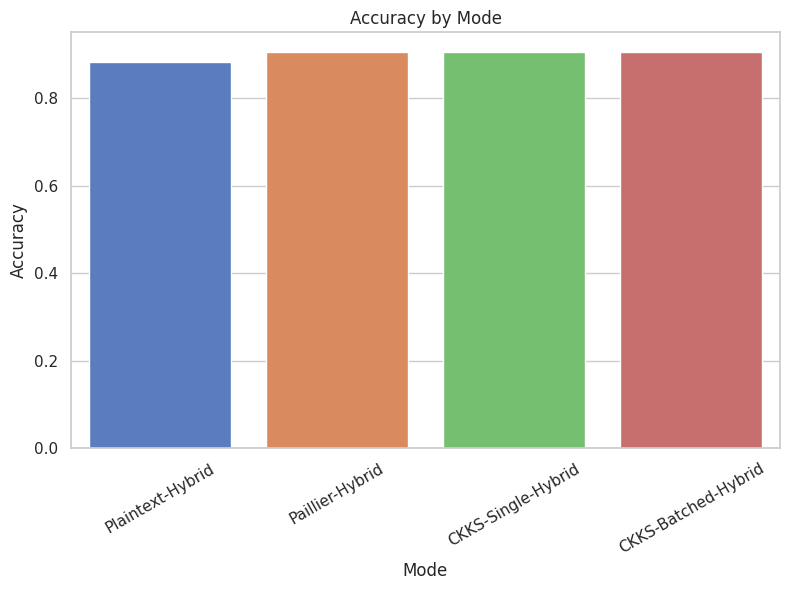

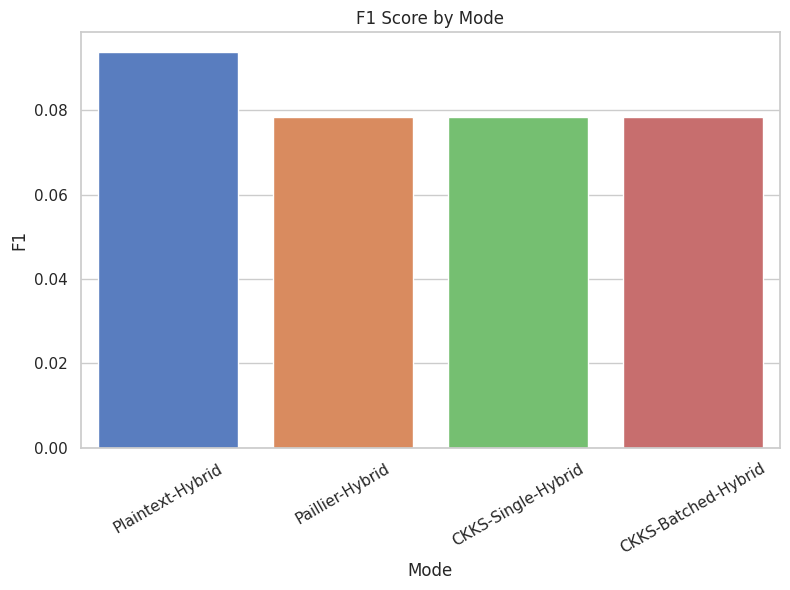

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Diabetes 130-US hospitals (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc
import os
import urllib.request # Import urllib.request
import zipfile # Import zipfile

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Diabetes 130 dataset)
# ========================================

# Download and extract Diabetes 130 dataset if not already present
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00296/dataset_diabetes.zip"
zip_file = "dataset_diabetes.zip"
csv_file = "dataset_diabetes/diabetic_data.csv"  # <-- FIXED PATH

if not os.path.exists(csv_file):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_file)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall(".")
        print("Files extracted:", zip_ref.namelist())

    print("Downloaded and extracted dataset.")

# Now read the CSV
df = pd.read_csv(csv_file)
print("Dataset loaded. Shape:", df.shape)
# Drop identifier columns
drop_cols = ["encounter_id", "patient_nbr", "weight", "payer_code", "medical_specialty"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Target: readmitted (<30 = 1, else 0)
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if str(x).strip() == "<30" else 0)
y = df["readmitted"]
df = df.drop(columns=["readmitted"])

# Handle missing values ("?")
df = df.replace("?", np.nan)
df = df.dropna(axis=1, thresh=0.9*len(df))
df = df.fillna("Unknown")

# Feature engineering (bin numeric vars)
for col in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
    if col in df.columns:
        df[col + "_binned"] = pd.cut(df[col], bins=5, labels=False)

# One-hot encode categorical vars
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - top 50
selector = SelectKBest(score_func=f_classif, k=min(50, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance train
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 500
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# **Diabetes Dataset 1000 Samples**

Extracting dataset...
Files extracted: ['dataset_diabetes/diabetic_data.csv', 'dataset_diabetes/IDs_mapping.csv']
Downloaded and extracted dataset.
Dataset loaded. Shape: (101766, 50)
Shapes -> X_train_bal: (115720, 50), X_val_s: (16283, 50), X_test_s: (20354, 50)
Training Hybrid XGBoost + MLP Feature Extractor...
Best parameters: {'C': 0.1}, Best score: 0.9734
Optimal threshold: 0.210 (F1: 0.2505)

=== Plaintext Inference ===
[Plaintext-Hybrid] inference in 0.002s | tuned threshold = 0.210

=== Paillier Homomorphic Encryption ===
[Paillier-Hybrid] inference (1000 samples) in 14.255s

=== CKKS Homomorphic Encryption (Single-sample) ===
[CKKS-Single-Hybrid] inference (1000 samples) in 31.746s
Memory after CKKS-Single: 1999.79 MB

=== CKKS Homomorphic Encryption (Batched) ===
[CKKS-Batched-Hybrid] inference (1000 samples) in 10.883s
Memory after CKKS-Batched: 1999.79 MB

=== Evaluation Results ===
                  Mode  Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  LogLoss   Bri

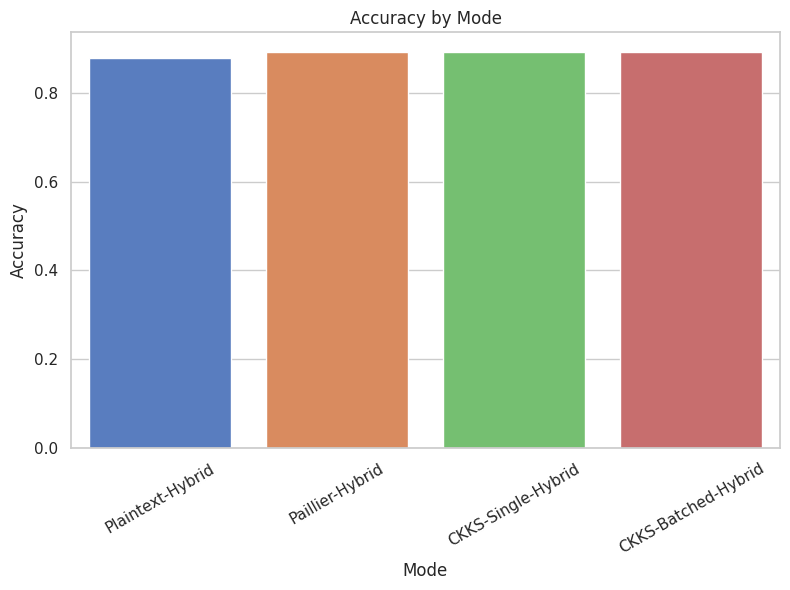

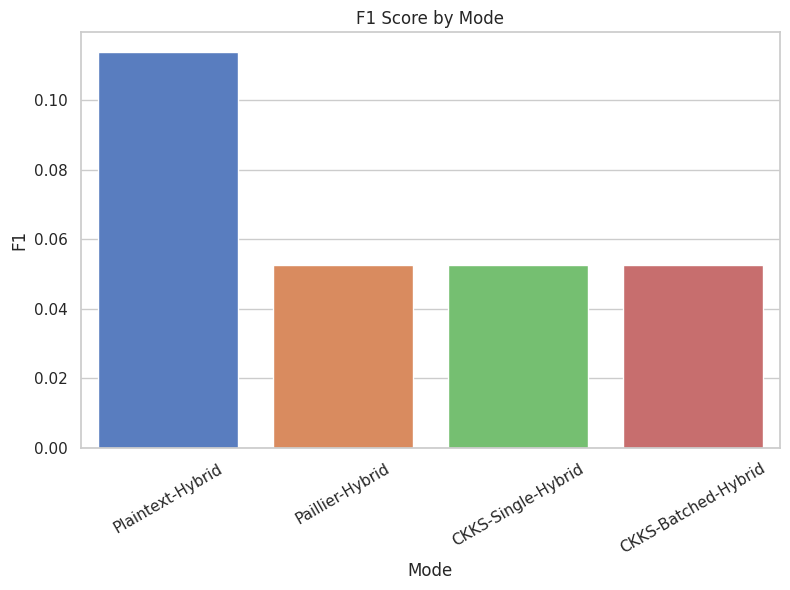

In [ ]:
# =============================================================================
# Colab-Ready: XGBoost+MLP Hybrid with Homomorphic Encryption
# =============================================================================
# Dataset: Diabetes 130-US hospitals (UCI) – auto-downloaded
# Modes: Plaintext, Paillier, CKKS-Single, CKKS-Batched
# =============================================================================

# Install required packages (run once in Colab)
!pip install -q tenseal phe imbalanced-learn xgboost tensorflow matplotlib seaborn

import time
import tenseal as ts
import phe as paillier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import psutil
import gc
import os
import urllib.request # Import urllib.request
import zipfile # Import zipfile

from math import isfinite

warnings.filterwarnings('ignore')

# sklearn & imblearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, log_loss, brier_score_loss
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE

# xgboost & tensorflow
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Memory monitoring
def monitor_memory():
    process = psutil.Process()
    memory_info = process.memory_info()
    return memory_info.rss / 1024 ** 2  # MB

# ========================================
# 1) Data loading & preprocessing (Diabetes 130 dataset)
# ========================================

# Download and extract Diabetes 130 dataset if not already present
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00296/dataset_diabetes.zip"
zip_file = "dataset_diabetes.zip"
csv_file = "dataset_diabetes/diabetic_data.csv"  # <-- FIXED PATH

if not os.path.exists(csv_file):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, zip_file)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_file, 'r') as zip_ref:
        zip_ref.extractall(".")
        print("Files extracted:", zip_ref.namelist())

    print("Downloaded and extracted dataset.")

# Now read the CSV
df = pd.read_csv(csv_file)
print("Dataset loaded. Shape:", df.shape)
# Drop identifier columns
drop_cols = ["encounter_id", "patient_nbr", "weight", "payer_code", "medical_specialty"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Target: readmitted (<30 = 1, else 0)
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if str(x).strip() == "<30" else 0)
y = df["readmitted"]
df = df.drop(columns=["readmitted"])

# Handle missing values ("?")
df = df.replace("?", np.nan)
df = df.dropna(axis=1, thresh=0.9*len(df))
df = df.fillna("Unknown")

# Feature engineering (bin numeric vars)
for col in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
    if col in df.columns:
        df[col + "_binned"] = pd.cut(df[col], bins=5, labels=False)

# One-hot encode categorical vars
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Feature selection - top 50
selector = SelectKBest(score_func=f_classif, k=min(50, df.shape[1]))
X_selected = selector.fit_transform(df, y)
selected_mask = selector.get_support()
selected_features = df.columns[selected_mask]
X = pd.DataFrame(X_selected, columns=selected_features)

# cleanup
del df
gc.collect()

# Train/val/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train_full
)

# Scale
scaler = StandardScaler(with_mean=True, with_std=True)
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

# Balance train
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_bal, y_train_bal = sm.fit_resample(X_train_s, y_train)

del X_train, X_val
gc.collect()

print(f"Shapes -> X_train_bal: {X_train_bal.shape}, X_val_s: {X_val_s.shape}, X_test_s: {X_test_s.shape}")

# ========================================
# 2) Hybrid XGBoost + MLP Model Training
# ========================================
print("Training Hybrid XGBoost + MLP Feature Extractor...")

# XGBoost feature extractor
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_bal, y_train_bal)
X_train_xgb = xgb_model.predict_proba(X_train_bal)
X_val_xgb = xgb_model.predict_proba(X_val_s)

# MLP feature extractor
input_dim = X_train_bal.shape[1]
hidden_units = 32

input_layer = Input(shape=(input_dim,))
hidden1 = Dense(hidden_units, activation='relu')(input_layer)
hidden2 = Dense(hidden_units // 2, activation='relu')(hidden1)
output_layer = Dense(1, activation='sigmoid')(hidden2)

mlp_model = Model(inputs=input_layer, outputs=output_layer)
mlp_model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

mlp_model.fit(X_train_bal, y_train_bal,
              epochs=30, batch_size=64,
              validation_data=(X_val_s, y_val),
              verbose=0)

feature_extractor = Model(inputs=mlp_model.input, outputs=hidden2)
X_train_mlp = feature_extractor.predict(X_train_bal, verbose=0)
X_val_mlp = feature_extractor.predict(X_val_s, verbose=0)

# Combine features
X_train_hybrid = np.hstack((X_train_xgb, X_train_mlp))
X_val_hybrid = np.hstack((X_val_xgb, X_val_mlp))

# Logistic Regression meta-learner with grid search
logreg_hybrid = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, tol=1e-4
)

param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

gs_hybrid = GridSearchCV(
    estimator=logreg_hybrid,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=0
)
gs_hybrid.fit(X_train_hybrid, y_train_bal)

print(f"Best parameters: {gs_hybrid.best_params_}, Best score: {gs_hybrid.best_score_:.4f}")

# Threshold tuning
val_scores_hybrid = gs_hybrid.best_estimator_.predict_proba(X_val_hybrid)[:, 1]
thresholds = np.linspace(0.2, 0.8, 61)
best_thr, best_f1 = 0.5, -1
for t in thresholds:
    preds = (val_scores_hybrid >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1, best_thr = f1, t
print(f"Optimal threshold: {best_thr:.3f} (F1: {best_f1:.4f})")

# Retrain on full train
X_train_full_s = scaler.fit_transform(X_train_full)
X_train_full_bal, y_train_full_bal = sm.fit_resample(X_train_full_s, y_train_full)

X_train_full_xgb = xgb_model.predict_proba(X_train_full_bal)
X_train_full_mlp = feature_extractor.predict(X_train_full_bal, verbose=0)
X_train_full_hybrid = np.hstack((X_train_full_xgb, X_train_full_mlp))

best_model_final = LogisticRegression(
    penalty="l2", solver="saga", max_iter=2000, class_weight="balanced",
    n_jobs=-1, random_state=RANDOM_STATE, **gs_hybrid.best_params_
)
best_model_final.fit(X_train_full_hybrid, y_train_full_bal)

weights = best_model_final.coef_[0].astype(float)
bias = float(best_model_final.intercept_[0])

del X_train_bal, y_train_bal, X_train_full_bal, y_train_full_bal, X_train_full_s
gc.collect()

# ========================================
# Helpers
# ========================================
def evaluate_model(y_true, y_pred, y_score, label):
    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, zero_division=0)
    rec   = recall_score(y_true, y_pred, zero_division=0)
    f1    = f1_score(y_true, y_pred, zero_division=0)
    rocau = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    prauc = average_precision_score(y_true, y_score) if len(np.unique(y_true)) > 1 else np.nan
    ll    = log_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    bs    = brier_score_loss(y_true, np.clip(y_score, 1e-12, 1-1e-12))
    return {
        "Mode": label, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "ROC-AUC": rocau, "PR-AUC": prauc, "LogLoss": ll, "Brier": bs
    }

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1.0 / (1.0 + np.exp(-x))

results = []

# ========================================
# 3) Plaintext Inference
# ========================================
print("\n=== Plaintext Inference ===")
X_test_xgb = xgb_model.predict_proba(X_test_s)
X_test_mlp = feature_extractor.predict(X_test_s, verbose=0)
X_test_hybrid = np.hstack((X_test_xgb, X_test_mlp))

start = time.time()
logits = np.dot(X_test_hybrid, weights) + bias
plaintext_probs = sigmoid(logits)
plaintext_preds = (plaintext_probs >= best_thr).astype(int)
plaintext_time = time.time() - start

results.append(evaluate_model(y_test.to_numpy(), plaintext_preds, plaintext_probs, "Plaintext-Hybrid"))
print(f"[Plaintext-Hybrid] inference in {plaintext_time:.3f}s | tuned threshold = {best_thr:.3f}")

del logits
gc.collect()

# ========================================
# 4) Paillier Homomorphic Encryption
# ========================================
print("\n=== Paillier Homomorphic Encryption ===")
pk, sk = paillier.generate_paillier_keypair(n_length=1024)

enc_weights = [pk.encrypt(float(w)) for w in weights]
enc_bias = pk.encrypt(float(bias))

fixed_sample_size = 1000
sample_size = min(fixed_sample_size, X_test_hybrid.shape[0])
X_sample_hybrid = X_test_hybrid[:sample_size]
y_sample = y_test.to_numpy()[:sample_size]

start = time.time()
enc_logits = []
for xi in X_sample_hybrid:
    dot = enc_bias
    for xij, enc_wj in zip(xi, enc_weights):
        dot = dot + enc_wj * float(xij)
    enc_logits.append(dot)

decrypted_logits = np.array([sk.decrypt(val) for val in enc_logits], dtype=float)
decrypted_logits[~np.isfinite(decrypted_logits)] = 0.0
paillier_probs = sigmoid(decrypted_logits)
paillier_preds = (paillier_probs >= best_thr).astype(int)
paillier_time = time.time() - start

results.append(evaluate_model(y_sample, paillier_preds, paillier_probs, "Paillier-Hybrid"))
print(f"[Paillier-Hybrid] inference ({sample_size} samples) in {paillier_time:.3f}s")

del enc_weights, enc_bias, enc_logits, decrypted_logits
gc.collect()

# ========================================
# 5) CKKS Homomorphic Encryption (Single-sample)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Single-sample) ===")

def build_ckks_context(poly_mod=8192, coeff_mod_bit_sizes=[60, 40, 40, 60], scale=2**40):
    ctx = ts.context(ts.SCHEME_TYPE.CKKS, poly_mod, -1, coeff_mod_bit_sizes)
    ctx.generate_galois_keys()
    ctx.global_scale = scale
    return ctx

ckks_single_time = float('nan')
try:
    context = build_ckks_context()

    enc_weights_ckks = ts.ckks_vector(context, weights.tolist())
    enc_bias_ckks = ts.ckks_vector(context, [bias])

    start = time.time()
    enc_logits_ckks = []
    for xi in X_sample_hybrid:
        enc_xi = ts.ckks_vector(context, xi.tolist())
        dot_product = enc_xi.dot(enc_weights_ckks)
        encrypted_logit = dot_product + enc_bias_ckks
        enc_logits_ckks.append(encrypted_logit)

    decrypted_logits_ckks = np.array([vec.decrypt()[0] for vec in enc_logits_ckks], dtype=float)
    ckks_single_probs = sigmoid(decrypted_logits_ckks)
    ckks_single_preds = (ckks_single_probs >= best_thr).astype(int)
    ckks_single_time = time.time() - start

    results.append(evaluate_model(y_sample, ckks_single_preds, ckks_single_probs, "CKKS-Single-Hybrid"))
    print(f"[CKKS-Single-Hybrid] inference ({sample_size} samples) in {ckks_single_time:.3f}s")

except Exception as e:
    print(f"CKKS-Single failed: {e}")
    results.append({
        "Mode": "CKKS-Single-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_vars = ['context', 'enc_weights_ckks', 'enc_bias_ckks', 'enc_logits_ckks', 'decrypted_logits_ckks']
for var in ckks_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Single: {monitor_memory():.2f} MB")

# ========================================
# 6) CKKS Homomorphic Encryption (Batched)
# ========================================
print("\n=== CKKS Homomorphic Encryption (Batched) ===")

ckks_batch_time = float('nan')
try:
    context = build_ckks_context()
    batch_size = min(16, sample_size)
    num_batches = int(np.ceil(sample_size / batch_size))

    start = time.time()
    decrypted_logits_batch = []

    for b in range(num_batches):
        batch_start = b * batch_size
        batch_end = min((b + 1) * batch_size, sample_size)
        current_bs = batch_end - batch_start
        batch_samples = X_sample_hybrid[batch_start:batch_end]

        weighted_sum = None
        for j in range(batch_samples.shape[1]):
            col_data = batch_samples[:, j].astype(float).tolist()
            enc_col = ts.ckks_vector(context, col_data)
            weighted_col = enc_col * float(weights[j])
            weighted_sum = weighted_col if weighted_sum is None else (weighted_sum + weighted_col)

        batch_bias = ts.ckks_vector(context, [float(bias)] * current_bs)
        encrypted_logits_batch = weighted_sum + batch_bias

        decrypted_logits_batch.extend(encrypted_logits_batch.decrypt())

    decrypted_logits_batch = np.array(decrypted_logits_batch, dtype=float)
    ckks_batch_probs = sigmoid(decrypted_logits_batch)
    ckks_batch_preds = (ckks_batch_probs >= best_thr).astype(int)
    ckks_batch_time = time.time() - start

    results.append(evaluate_model(y_sample[:len(ckks_batch_preds)], ckks_batch_preds, ckks_batch_probs, "CKKS-Batched-Hybrid"))
    print(f"[CKKS-Batched-Hybrid] inference ({len(ckks_batch_preds)} samples) in {ckks_batch_time:.3f}s")

except Exception as e:
    print(f"CKKS-Batched failed: {e}")
    results.append({
        "Mode": "CKKS-Batched-Hybrid", "Accuracy": np.nan, "Precision": np.nan,
        "Recall": np.nan, "F1": np.nan, "ROC-AUC": np.nan, "PR-AUC": np.nan, "LogLoss": np.nan, "Brier": np.nan
    })

ckks_batch_vars = ['context', 'weighted_sum', 'batch_bias', 'encrypted_logits_batch', 'decrypted_logits_batch']
for var in ckks_batch_vars:
    if var in locals():
        del locals()[var]
gc.collect()

print(f"Memory after CKKS-Batched: {monitor_memory():.2f} MB")

# ========================================
# 7) Results Analysis & Plots
# ========================================
df_results = pd.DataFrame(results)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1500)
print("\n=== Evaluation Results ===")
print(df_results.round(4))

# Degradation vs plaintext
if 'Plaintext-Hybrid' in df_results['Mode'].values:
    plaintext_metrics = df_results[df_results['Mode'] == 'Plaintext-Hybrid'].iloc[0]
    degradation = []
    for _, row in df_results.iterrows():
        if row['Mode'] != 'Plaintext-Hybrid' and not np.isnan(row['Accuracy']):
            acc_diff = row['Accuracy'] - plaintext_metrics['Accuracy']
            f1_diff = row['F1'] - plaintext_metrics['F1']
            degradation.append({"Mode": row['Mode'], "ΔAccuracy": acc_diff, "ΔF1": f1_diff})
    df_degradation = pd.DataFrame(degradation)
    print("\n=== Performance Degradation vs Plaintext ===")
    print(df_degradation.round(4))

# Plots
plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="Accuracy", data=df_results, palette="muted")
plt.title("Accuracy by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Mode", y="F1", data=df_results, palette="muted")
plt.title("F1 Score by Mode")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
